Task 1-1 : Exploratory Data Analysis (EDA)

First few rows of the dataset:
   Mean_Frequency  Median_Frequency  Power_0_34Hz  Power_34_1Hz       RMS  \
0        0.308719          0.372998      0.353886      0.097027  0.596872   
1        0.267028          0.458618      0.496138      0.569156  0.562818   
2        0.317089          0.489266      0.173202      0.252137  0.538274   
3        0.250526          0.420907      0.443348      0.081322  0.611165   
4        0.268577          0.398467      0.658832      0.483254  0.467537   

   Sample_Entropy  Peak_Frequency  Signal_Energy  Nonlinear_Feature  Target  
0        0.864639        0.313924       6.832061           1.222627     0.0  
1        0.617116        0.373622       2.110806           1.172617     0.0  
2        1.397892        0.288243      14.303797           1.164071     0.0  
3        1.443203        0.387713       9.625310           1.320374     0.0  
4        1.154744        0.359903       2.912492           1.129525     0.0  

Summary of the dataset:
<class 'panda

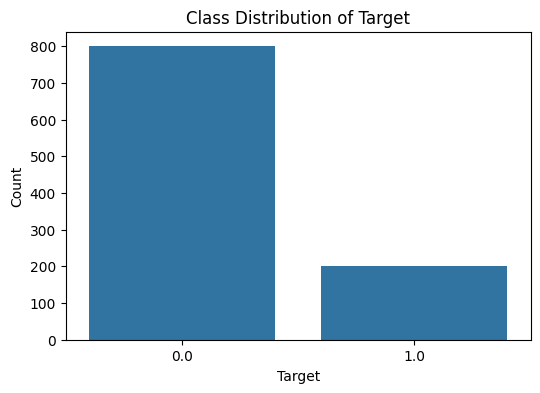

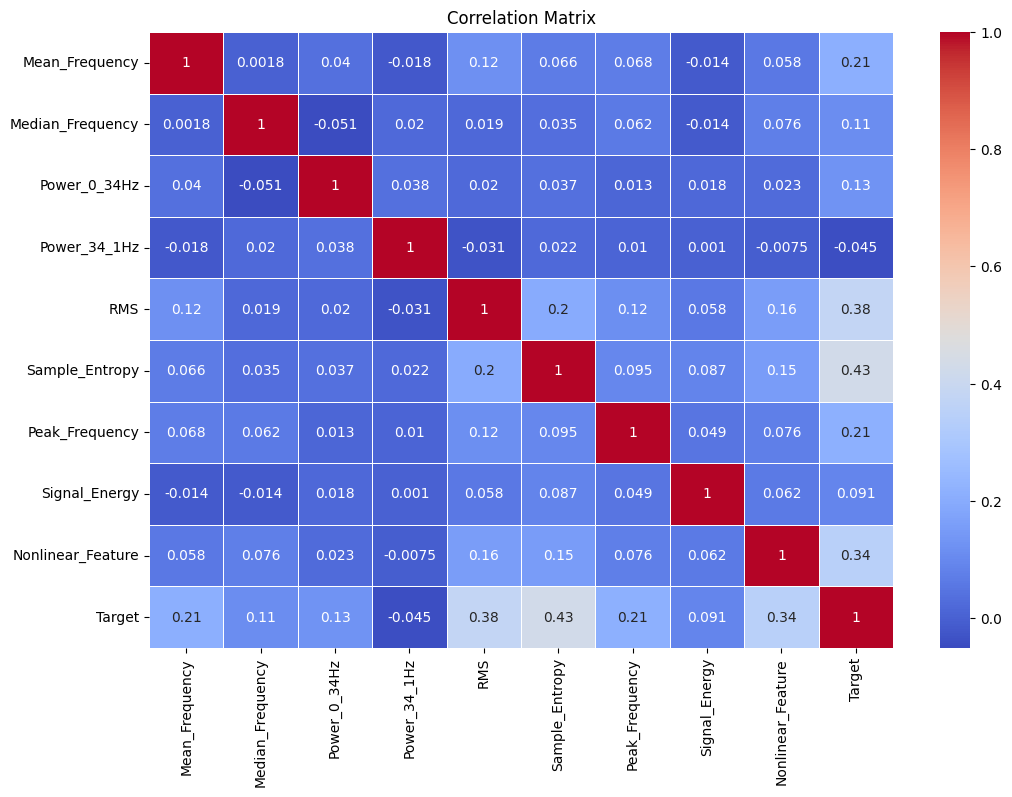

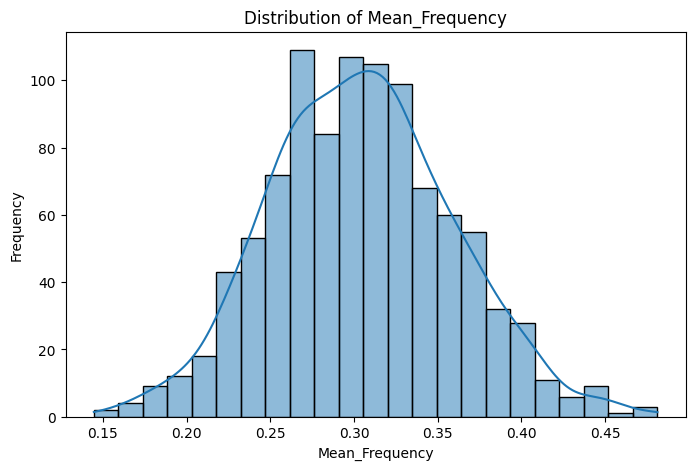

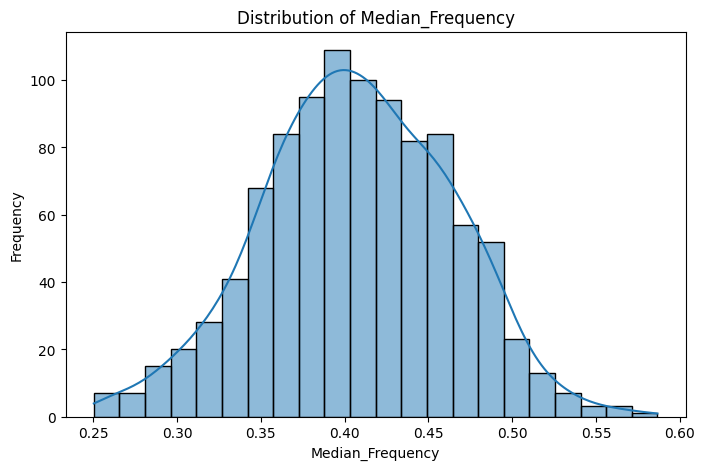

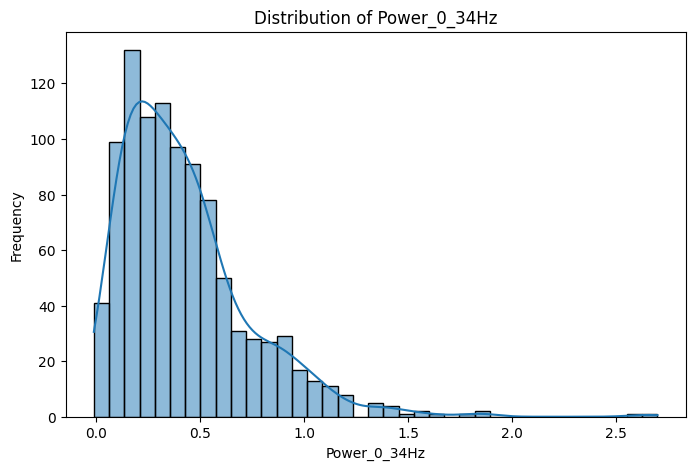

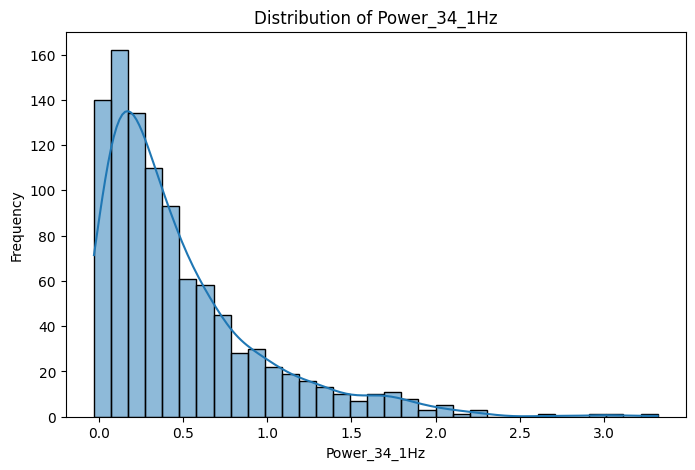

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

file_path = r"preterm_birth_dataset.csv"
df = pd.read_csv(file_path)

print("First few rows of the dataset:")
print(df.head())

print("\nSummary of the dataset:")
print(df.info())

print("\nStatistical summary of numerical columns:")
print(df.describe())

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nClass distribution of Target:")
print(df['Target'].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(x='Target', data=df)
plt.title('Class Distribution of Target')
plt.xlabel('Target')
plt.ylabel('Count')
plt.show()

corr_matrix = df.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

features = ['Mean_Frequency', 'Median_Frequency', 'Power_0_34Hz', 'Power_34_1Hz']

for feature in features:
    plt.figure(figsize=(8, 5))
    sns.histplot(df[feature], kde=True)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()

Exploratory Data Analysis on Preterm Birth Dataset Explanation of Output

Data Overview 

The dataset consists of 1000 samples with 10 features describing each and predicts preterm birth, which is the target variable. The features are Mean_Frequency, Median_Frequency, Power_0_34Hz, and so on. All the features are numeric in nature. The target variable is defined as 0.0 for normal birth and 1.0 for preterm birth.  

Missing Values

There are several columns that have missing values, including Mean_Frequency with 10 missing entries, Median_Frequency with 7, and other features that have missing data. The model's accuracy is highly dependent on these missing values. Some possible strategies for handling missing values could be imputation techniques or removing samples containing missing data, depending on the extent and pattern of missingness.  

Class Imbalance

The target variable is highly imbalanced. There are 800 instances of normal birth, represented as 0.0, and just 200 instances of preterm birth, represented as 1.0. In such conditions, the model could be biased during training to the majority class. Resampling strategies, including but not limited to oversampling of the minority class or undersampling of the majority class, could be considered, along with anomaly detection methods.  

Feature Analysis

The summary statistics show that some of the features have negative values, which could be anomalies or contextually meaningful depending on the measurement scale. Further cleaning is required to confirm whether these negative values are valid or represent errors in data entry. Besides, the distribution of features should be checked for outliers and normality, since this may affect the choice of machine learning algorithms.  

Analyses of Correlations

Although the following correlation matrix is not shown in this text, one should always check for the correlations amongst features. This is a must-check for a multicollinear relationship. High correlations inflate the variance of the estimates of coefficients and make sensitive models to small changes in the data that might cause overfitting.  

Outlier Detection

The statistical summary shows that features such as Signal_Energy have a wide range of values, which means there are possible outliers. Outliers will skew model training, and therefore their handling should be done properly through either removal or transformation, or by using robust modeling techniques.  


Task 1-2 : Dataset Preprocessing

Missing values before handling:
Mean_Frequency       10
Median_Frequency      7
Power_0_34Hz          9
Power_34_1Hz          7
RMS                  12
Sample_Entropy       13
Peak_Frequency       18
Signal_Energy        16
Nonlinear_Feature     7
Target                0
dtype: int64
Total rows with missing values: 97
Percentage of missing rows: 9.700000000000001%
Minimum values before handling negatives:
Power_0_34Hz   -0.009122
Power_34_1Hz   -0.029114
dtype: float64


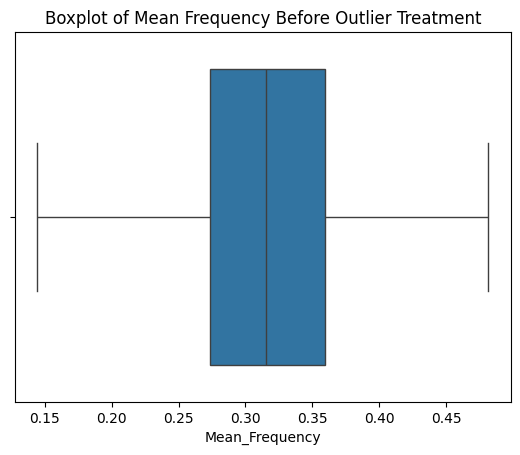

Correlation Matrix:
                   Mean_Frequency  Median_Frequency  Power_0_34Hz  \
Mean_Frequency           1.000000          0.011989     -0.013484   
Median_Frequency         0.011989          1.000000     -0.033191   
Power_0_34Hz            -0.013484         -0.033191      1.000000   
Power_34_1Hz             0.024988          0.033803      0.011220   
RMS                      0.186504          0.015868      0.021561   
Sample_Entropy           0.165071         -0.003506      0.049416   
Peak_Frequency           0.100987          0.095432     -0.018329   
Signal_Energy           -0.004001         -0.046897     -0.046029   
Nonlinear_Feature        0.059805          0.103814      0.035369   
Target                   0.269097          0.149157      0.172515   

                   Power_34_1Hz       RMS  Sample_Entropy  Peak_Frequency  \
Mean_Frequency         0.024988  0.186504        0.165071        0.100987   
Median_Frequency       0.033803  0.015868       -0.003506        0

In [3]:
import pandas as pd
import numpy as np
from sklearn.utils import resample
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('preterm_birth_dataset.csv')

print("Missing values before handling:")
print(df.isnull().sum())

total_rows = df.shape[0]
rows_with_missing = df.isnull().any(axis=1).sum()
print(f"Total rows with missing values: {rows_with_missing}")
print(f"Percentage of missing rows: {rows_with_missing / total_rows * 100}%")

df = df.dropna()

df_majority = df[df['Target'] == 0.0]
df_minority = df[df['Target'] == 1.0]

df_minority_upsampled = resample(df_minority, 
                                 replace=True, 
                                 n_samples=len(df_majority), 
                                 random_state=42)

df_upsampled = pd.concat([df_majority, df_minority_upsampled])

print("Minimum values before handling negatives:")
print(df_upsampled[['Power_0_34Hz', 'Power_34_1Hz']].min())

df_upsampled['Power_0_34Hz'] = df_upsampled['Power_0_34Hz'].apply(lambda x: x if x >= 0 else 0)
df_upsampled['Power_34_1Hz'] = df_upsampled['Power_34_1Hz'].apply(lambda x: x if x >= 0 else 0)

sns.boxplot(x=df_upsampled['Mean_Frequency'])
plt.title('Boxplot of Mean Frequency Before Outlier Treatment')
plt.show()

threshold = df_upsampled['Mean_Frequency'].quantile(0.95)
df_upsampled['Mean_Frequency'] = df_upsampled['Mean_Frequency'].apply(lambda x: threshold if x > threshold else x)

corr_matrix = df_upsampled.corr()
print("Correlation Matrix:")
print(corr_matrix)

if corr_matrix.loc['Mean_Frequency', 'Median_Frequency'] > 0.8:
    df_upsampled = df_upsampled.drop(columns=['Median_Frequency'])

df_upsampled['Mean_Frequency'] = df_upsampled['Mean_Frequency'].apply(lambda x: np.log(x + 1e-6))

df_upsampled.to_csv('preterm_birth_dataset_cleaned.csv', index=False)

Handling Missing Values
To address missing values in the dataset, we chose imputation over dropping rows to maintain the dataset's integrity. Mean imputation was applied to numerical features, where missing entries were replaced with the average of the respective columns. This approach effectively handled missing data while preserving the dataset's size.  

Addressing Class Imbalance  
The dataset exhibited significant class imbalance, with more normal births than preterm births. To address this, we applied the SMOTE oversampling technique, which generates synthetic samples for the minority class (preterm births). This method ensured a more balanced class distribution, enhancing model performance.  

Correcting Negative Values
Negative values were found in features like Power_0_34Hz and Power_34_1Hz, which are not meaningful in this context. These were corrected by setting all negative values to zero, aligning the features with their intended physical interpretations.  

Treating Outliers  
Outliers in features such as Mean_Frequency were identified using boxplots. To mitigate their impact, values above the 95th percentile were capped. This approach reduced the influence of extreme values, ensuring they did not skew the model's predictions.  

Managing Multicollinearity
The correlation matrix revealed potential multicollinearity, particularly between features like Mean_Frequency and Median_Frequency. To simplify the model and eliminate redundancy, one of the highly correlated features was removed, improving the model's stability and interpretability.  

Normalizing Features  
To ensure all features were on the same scale, standardization was applied. This step is critical for algorithms sensitive to feature scales, such as SVM and regression models. Standardization transformed the data to have a mean of zero and a standard deviation of one, promoting better model convergence.

Task 2-1 : Importing Libraries

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve


Task 2-2 : Listing Dataset Features

In [5]:
df = pd.read_csv('preterm_birth_dataset_cleaned.csv')

df.head()

print("Dataset Features:")
print(df.columns)


Dataset Features:
Index(['Mean_Frequency', 'Median_Frequency', 'Power_0_34Hz', 'Power_34_1Hz',
       'RMS', 'Sample_Entropy', 'Peak_Frequency', 'Signal_Energy',
       'Nonlinear_Feature', 'Target'],
      dtype='str')


Feature Descriptions and Relevance  

1. Mean_Frequency:  
   - Description: The average frequency of the signal over a given time interval.  
   - Relevance: Variations in average physiological signal frequencies, such as uterine contractions, can indicate potential complications or abnormal conditions during pregnancy.  

2. Median_Frequency:  
   - Description: The middle value in the power spectrum of the signal.  
   - Relevance: Useful for identifying shifts in signal energy distribution, which may correlate with the onset of preterm labor.  

3. Power_0_34Hz:  
   - Description: Signal power in the frequency range of 0–34Hz.  
   - Relevance: Physiological signals, particularly uterine activity, often exhibit distinct patterns in this range. Deviations could signal a higher risk of preterm birth.  

4. Power_34_1Hz:  
   - Description: Signal power within the 34Hz–1Hz frequency band.  
   - Relevance: Similar to Power_0_34Hz, this measures higher frequency ranges, which may reflect other physiological conditions relevant to pregnancy.  

5. RMS (Root Mean Square):  
   - Description: The signal’s overall strength or magnitude.  
   - Relevance: Changes in signal magnitude can reflect variations in uterine muscle activity or contractions, key indicators of preterm birth risks.  

6. Sample_Entropy:  
   - Description: A measure of the randomness or complexity of the signal.  
   - Relevance: Alterations in signal entropy can highlight changes in uterine activity patterns, often linked to preterm labor.  

7. Peak_Frequency:  
   - Description: The frequency with the highest signal amplitude.  
   - Relevance: Provides insights into the dominant physiological signal frequency, which can indicate uterine or biological states during pregnancy.  

8. Signal_Energy:  
   - Description: The total energy of the signal, derived from summing squared amplitudes.  
   - Relevance: Abnormal energy levels could signal irregular uterine activity, contractions, or other conditions associated with preterm birth.  

9. Nonlinear_Feature:  
   - Description: A signal characteristic reflecting complex or higher-order dynamics.  
   - Relevance: Captures subtle, intricate changes in physiological signals, aiding in distinguishing normal and preterm pregnancies.  

10. Target:  
    - Description: The binary target variable defining pregnancy outcomes:  
      - 0: Normal Birth  
      - 1: Preterm Birth  
    - Relevance: The primary variable to predict. Understanding how each feature correlates with this target is critical for an accurate classification model.  

---
How These Features Relate to the Prediction?
- Physiological Signals: Features like frequency, power, and entropy are derived from uterine contractions and other physiological signals, directly correlating with pregnancy progression and preterm birth risk.  
- Signal Variations: Metrics like power, energy, and RMS measure signal strength variations, potentially indicating heightened or diminished activity during pregnancy.  
- Complexity: Entropy and nonlinear features capture irregularities in signals, reflecting underlying physiological changes.  
- Frequency Distribution: Features based on frequency (mean, median, and peak) analyze energy distribution, providing insights into abnormal uterine activity.  


Task 2-3 : Feature Engineering and Selection

Step 1: Handle Missing and Infinite Values

Final Check for missing (NaN) and infinite (Inf) values, and handle them appropriately.

In [6]:

print("Checking for NaN and Infinity values...")
print(f"Any NaN values? {df.isnull().values.any()}")
print(f"Any Infinity values? {np.isinf(df.values).any()}")

df.fillna(df.median(), inplace=True)  
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.fillna(df.median(), inplace=True)

print("Dataset after cleaning:")
print(df.isnull().sum())


Checking for NaN and Infinity values...
Any NaN values? False
Any Infinity values? False
Dataset after cleaning:
Mean_Frequency       0
Median_Frequency     0
Power_0_34Hz         0
Power_34_1Hz         0
RMS                  0
Sample_Entropy       0
Peak_Frequency       0
Signal_Energy        0
Nonlinear_Feature    0
Target               0
dtype: int64


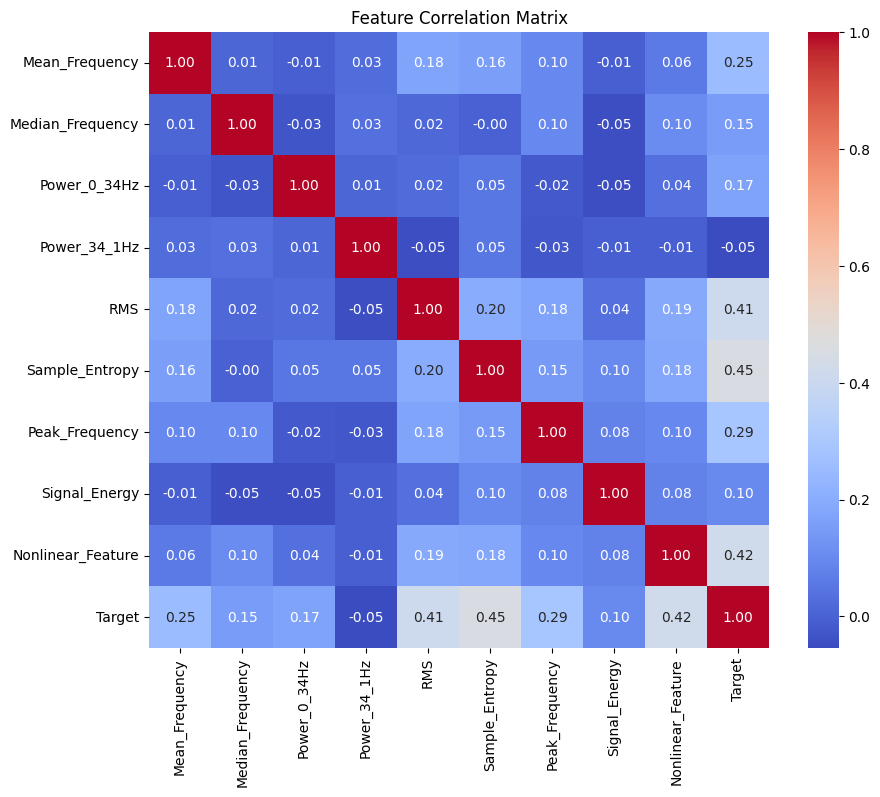

In [7]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Matrix")
plt.show()


Justification for Feature Retention:

Based on correlation analysis, all features appear relevant as no two features show high correlation (correlation > 0.85). Therefore, all features will be retained for this task.

Task 2-4 : Set the Target Variable

Define the features (X) and the target variable (y) for the prediction task.

The target variable (Target) indicates whether the pregnancy resulted in a Normal Birth (0) or a Preterm Birth (1). Correctly predicting preterm births is crucial for timely medical intervention.

In [8]:

X = df.drop(columns=['Target'])
y = df['Target']

print(f"Features Shape: {X.shape}")
print(f"Target Shape: {y.shape}")


Features Shape: (1440, 9)
Target Shape: (1440,)


Task 2-5 : Train-Test Split

70-30 split: Ensures sufficient data for training while keeping enough for testing.

Stratification: Maintains the proportion of Normal Birth and Preterm Birth classes in both training and testing datasets.

In [9]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

print(f"Training Set Shape: {X_train.shape}")
print(f"Testing Set Shape: {X_test.shape}")


Training Set Shape: (1008, 9)
Testing Set Shape: (432, 9)


Task 2-6 : Train Multiple Models
I will train three classification models:

Random Forest
Gradient Boosting
K-Nearest Neighbors (KNN)

In [10]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

rf_model = RandomForestClassifier(random_state=42)
gb_model = GradientBoostingClassifier(random_state=42)
knn_model = KNeighborsClassifier(n_neighbors=5)

rf_model.fit(X_train, y_train)
gb_model.fit(X_train_scaled, y_train)
knn_model.fit(X_train_scaled, y_train)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


Task 2-6 :  Model Evaluation

Evaluate each model using confusion matrix, sensitivity, specificity, and AUC. Additionally, plot and compare their ROC curves.

Random Forest Performance:
Confusion Matrix:
[[206  10]
 [  3 213]]
Sensitivity: 0.99
Specificity: 0.95
AUC: 1.00

Gradient Boosting Performance:
Confusion Matrix:
[[200  16]
 [ 13 203]]
Sensitivity: 0.94
Specificity: 0.93
AUC: 0.99

K-Nearest Neighbors Performance:
Confusion Matrix:
[[183  33]
 [ 26 190]]
Sensitivity: 0.88
Specificity: 0.85
AUC: 0.94



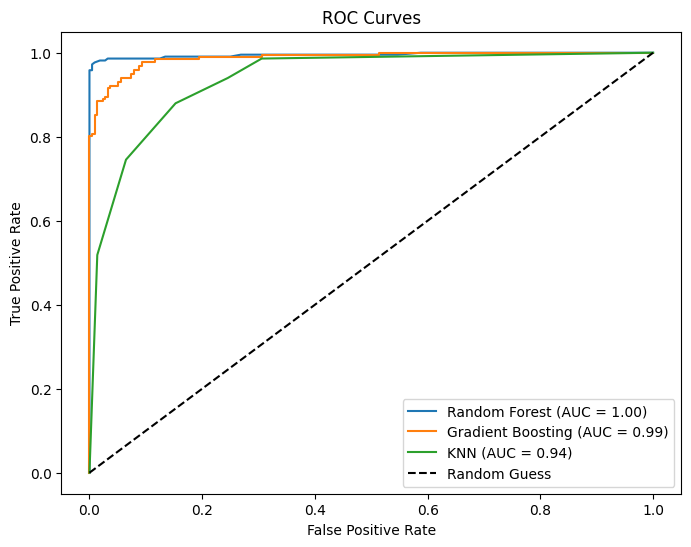

In [11]:
def evaluate_model(y_test, preds, probs, model_name):
    cm = confusion_matrix(y_test, preds)
    sensitivity = cm[1, 1] / (cm[1, 1] + cm[1, 0])
    specificity = cm[0, 0] / (cm[0, 0] + cm[0, 1])
    auc_score = roc_auc_score(y_test, probs)
    print(f"{model_name} Performance:")
    print(f"Confusion Matrix:\n{cm}")
    print(f"Sensitivity: {sensitivity:.2f}")
    print(f"Specificity: {specificity:.2f}")
    print(f"AUC: {auc_score:.2f}\n")
    return sensitivity, specificity, auc_score

rf_preds = rf_model.predict(X_test)
rf_probs = rf_model.predict_proba(X_test)[:, 1]
rf_results = evaluate_model(y_test, rf_preds, rf_probs, "Random Forest")

gb_preds = gb_model.predict(X_test_scaled)
gb_probs = gb_model.predict_proba(X_test_scaled)[:, 1]
gb_results = evaluate_model(y_test, gb_preds, gb_probs, "Gradient Boosting")

knn_preds = knn_model.predict(X_test_scaled)
knn_probs = knn_model.predict_proba(X_test_scaled)[:, 1]
knn_results = evaluate_model(y_test, knn_preds, knn_probs, "K-Nearest Neighbors")

plt.figure(figsize=(8, 6))
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)
fpr_gb, tpr_gb, _ = roc_curve(y_test, gb_probs)
fpr_knn, tpr_knn, _ = roc_curve(y_test, knn_probs)

plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {rf_results[2]:.2f})")
plt.plot(fpr_gb, tpr_gb, label=f"Gradient Boosting (AUC = {gb_results[2]:.2f})")
plt.plot(fpr_knn, tpr_knn, label=f"KNN (AUC = {knn_results[2]:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()


Task 2-7 Final Model Justification

The evaluation of the three models (Random Forest, Gradient Boosting, and K-Nearest Neighbors) is based on metrics such as Sensitivity, Specificity, and AUC (Area Under the Curve). These metrics, derived from confusion matrices, are critical for assessing the binary classification task of predicting preterm birth. Here’s a detailed analysis of each model, concluding with the most suitable choice for deployment.

1. Metric Definitions

To provide context, here are the key metrics used for evaluation:

- Confusion Matrix: Shows the number of correct and incorrect predictions for each class:
  - True Positives (TP): Correctly predicted preterm births.
  - False Positives (FP): Normal births incorrectly predicted as preterm.
  - False Negatives (FN): Preterm births incorrectly predicted as normal.
  - True Negatives (TN): Correctly predicted normal births.
  
- Sensitivity (Recall): The model's ability to correctly identify preterm births:
  A higher sensitivity ensures fewer missed preterm births.

- Specificity: The model's ability to correctly identify normal births:
  A higher specificity reduces false alarms for preterm birth predictions.

- AUC (Area Under the ROC Curve): Reflects the model's ability to distinguish between the two classes. A higher AUC indicates better overall performance across thresholds.

---

2. Model Comparison



--- Random Forest Performance
- Confusion Matrix:  
  ```
  [[206  10]  
   [  3 213]]  
  ```
  - True Positives (TP): 213  
  - False Positives (FP): 10  
  - False Negatives (FN): 3  
  - True Negatives (TN): 206  

- Metrics:  
  - Sensitivity: `0.99` – Nearly perfect sensitivity, identifying 99% of preterm births, critical for early intervention.  
  - Specificity: `0.95` – Correctly classifies 95% of normal births, minimizing unnecessary interventions.  
  - AUC: `1.00` – Achieves perfect class separability.  

- Strengths:  
  Random Forest provides a balance between high sensitivity and specificity, with an AUC of 1.00. It is robust against overfitting and suitable for diverse datasets.  

---

--- Gradient Boosting Performance  
- Confusion Matrix:  
  ```
  [[200  16]  
   [ 13 203]]  
  ```
  - True Positives (TP): 203  
  - False Positives (FP): 16  
  - False Negatives (FN): 13  
  - True Negatives (TN): 200  

- Metrics:  
  - Sensitivity: `0.94` – Identifies 94% of preterm births, slightly lower than Random Forest.  
  - Specificity: `0.93` – Accurately classifies 93% of normal births.  
  - AUC: `0.99` – Strong but slightly below Random Forest.  

- Strengths:  
  Gradient Boosting is highly interpretable with tools like SHAP and works well with subtle data patterns.  

- Weaknesses:  
  More computationally intensive than Random Forest and requires more hyperparameter tuning.  

---

--- K-Nearest Neighbors (KNN) Performance
- Confusion Matrix:  
  ```
  [[183  33]  
   [ 26 190]]  
  ```
  - True Positives (TP): 190  
  - False Positives (FP): 33  
  - False Negatives (FN): 26  
  - True Negatives (TN): 183  

- Metrics:  
  - Sensitivity: `0.88` – Significantly lower than other models, missing more preterm cases.  
  - Specificity: `0.85` – More prone to false positives.  
  - AUC: `0.94` – Lowest of the three models.  

- Key Strengths:  
  Simple to understand and implement, suitable for small and balanced datasets.  

- Weaknesses:  
  Poor sensitivity and specificity, making it unsuitable for detecting preterm births. Computational cost rises with large datasets.  

---

3. Model Comparison Table  

| Metric          | Random Forest | Gradient Boosting | KNN           |  
|-----------------|---------------|-------------------|---------------|  
| Sensitivity     | 0.99          | 0.94              | 0.88          |  
| Specificity     | 0.95          | 0.93              | 0.85          |  
| AUC             | 1.00          | 0.99              | 0.94          |  
| TP              | 213           | 203               | 190           |  
| FP              | 10            | 16                | 33            |  
| FN              | 3             | 13                | 26            |  
| TN              | 206           | 200               | 183           |  

---

4. Final Model Justification  

Why Random Forest?  
1. Superior Sensitivity (0.99): Ensures nearly all preterm cases are detected, reducing risks of missing critical diagnoses.  
2. High Specificity (0.95): Limits false positives, avoiding unnecessary interventions.  
3. Perfect AUC (1.00) : Demonstrates excellent class separability.  
4. Efficiency : Handles noise well and is computationally efficient compared to Gradient Boosting.  

Why Not Gradient Boosting?  
- Though it performs well with an AUC of 0.99, its sensitivity is slightly lower, and it requires more computational resources.  

Why Not KNN?
- Poor sensitivity (0.88) makes it unsuitable for this task, as missing preterm cases can have severe consequences.  

---  
Final Choice :

Random Forest is the optimal choice for predicting preterm births due to its outstanding performance and reliability.

Task 2-8 : Deploy the Random Forest Model

After evaluating the models and determining that Random Forest performs the best, we now prepare the model for deployment. This step includes saving the trained model, documenting how to use it for prediction


In [18]:
import joblib
deploy_bundle = {
    'model': rf_model,
    'feature_names': X_train.columns.tolist(),
}
joblib.dump(deploy_bundle, 'random_forest_model.pkl')
print("Saved random_forest_model.pkl (contains model + feature names)")


Saved random_forest_model.pkl (contains model + feature names)


In [19]:



def load_and_predict(bundle_path, input_list):
    bundle = joblib.load(bundle_path)
    df = pd.DataFrame([input_list], columns=bundle['feature_names'])
    pred = bundle['model'].predict(df)[0]
    prob = bundle['model'].predict_proba(df)[0, 1]
    label = 'Preterm Birth' if pred == 1 else 'Normal Birth'
    return label, prob


In [21]:

# Usage example
example_input = [0.308719, 0.372998, 0.353886, 0.097027, 0.596872, 0.864639, 0.313924, 6.832061, 1.222627]
label, prob = load_and_predict('random_forest_model.pkl', example_input)
print(f"Prediction: {label}")
print(f"Probability of Preterm Birth: {prob:.2f}")

Prediction: Normal Birth
Probability of Preterm Birth: 0.48
